# Customer Segmentation with Clustering
**Goal:** segment a set of wholesale customers into groups using k-means, decide how many
groups with the **elbow method** and the **silhouette score**, and explain what each segment is.



## Your dataset

Use the **Wholesale Customers** dataset: annual spending (monetary units) by 440 clients of a
wholesale distributor across product categories.

- Download: [UCI Wholesale Customers](https://archive.ics.uci.edu/dataset/292/wholesale+customers) (also searchable as "Wholesale customers" on Kaggle).
- Columns: `Channel`, `Region` (these are labels, not spending), then the six spend columns `Fresh`, `Milk`, `Grocery`, `Frozen`, `Detergents_Paper`, `Delicassen`.
- Cluster on the **six spend columns**. `Channel` and `Region` are context only; do not cluster on them.

In [56]:
# Step 0: imports (given - just run this)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
print("Ready.")

Ready.


## Step 1: Load the data

Change the path to the real Wholesale file when you have it.

In [57]:
# GIVEN: load the data
df = pd.read_csv("./wholesale_sample.csv")
spend_cols = ["Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicassen"]
df.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,1,1,4181,10024,26577,1979,9194,1151
1,2,3,3346,4848,14310,1155,2666,1768
2,2,3,3687,8096,10837,870,7701,1345
3,1,2,3008,6327,16926,1032,5303,1582
4,2,3,4704,13163,20537,1507,3073,1267


## Step 2: Explore

Look at the data before clustering: size, column types, and the ranges of the spend columns
(the ranges tell you whether scaling is needed).

In [58]:
# TODO: explore the data
df.shape
df.info()
df[spend_cols].describe()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           150 non-null    int64
 1   Region            150 non-null    int64
 2   Fresh             150 non-null    int64
 3   Milk              150 non-null    int64
 4   Grocery           150 non-null    int64
 5   Frozen            150 non-null    int64
 6   Detergents_Paper  150 non-null    int64
 7   Delicassen        150 non-null    int64
dtypes: int64(8)
memory usage: 9.5 KB


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,150.000000,150.000000,150.000000,150.000000,150.000000,150.000000
mean,10298.826667,5422.726667,7938.353333,3017.386667,2981.926667,1808.906667
std,8398.147983,3820.906314,7053.621991,1977.922844,2879.237096,950.893154
min,2043.000000,1313.000000,1451.000000,760.000000,318.000000,483.000000
25%,3923.250000,2524.250000,2877.750000,1461.500000,871.750000,1154.500000
50%,5748.500000,3740.000000,4497.500000,2113.000000,1370.500000,1581.000000
75%,17153.250000,8001.500000,12043.250000,4271.750000,5148.750000,2161.500000
max,35404.000000,18274.000000,34411.000000,8236.000000,12186.000000,5332.000000


## Step 3: Select features and scale

k-means uses distance, and these spend columns are on very different scales, so scale them.

- Build X from the six spend columns.
- Scale with StandardScaler.

In [59]:
# TODO: build X from the spend columns and scale it

X = df[spend_cols].values
Xs = StandardScaler().fit_transform(X)

## Step 4: Choose the number of clusters (elbow + silhouette)

Try a range of k (say 2 to 10). For each k, fit k-means and record two things:

- `kmeans.inertia_` for the **elbow** plot (tightness; look for where the curve bends),
- `silhouette_score(Xs, labels)` for the **silhouette** plot (separation; higher is better).

Plot both, then pick a k and justify it in a sentence.

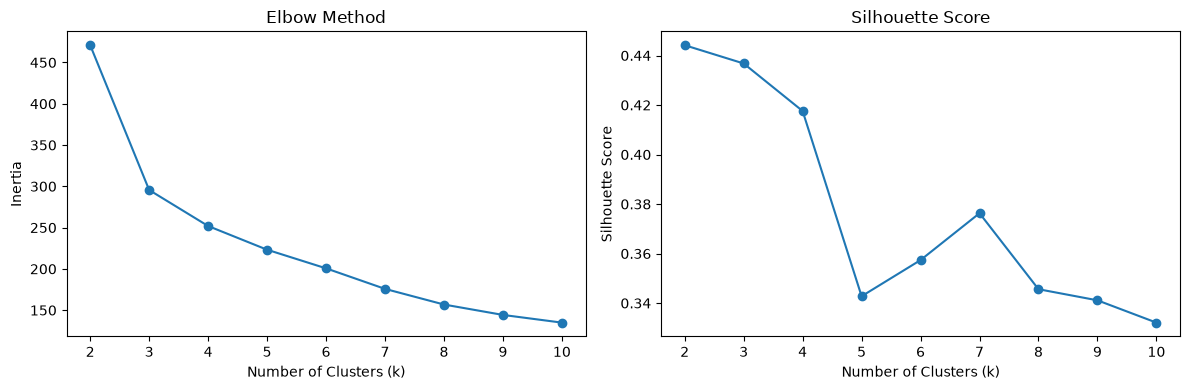

In [60]:
# TODO: loop over k, collect inertia and silhouette, then plot both
# Hint:
# ks = range(2, 11)
# inertias, sils = [], []
# for k in ks:
#     km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(Xs)
#     inertias.append(km.inertia_)
#     sils.append(silhouette_score(Xs, km.labels_))
# then make two plots: ks vs inertias, and ks vs sils

ks = range(2, 11)
inertias, sils = [], []
for k in ks:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(Xs)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(Xs, km.labels_))
    

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Elbow plot
axes[0].plot(ks, inertias, marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of Clusters (k)")
axes[0].set_ylabel("Inertia")
axes[0].set_xticks(ks)

# Silhouette plot
axes[1].plot(ks, sils, marker="o")
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of Clusters (k)")
axes[1].set_ylabel("Silhouette Score")
axes[1].set_xticks(ks)

plt.tight_layout()
plt.show()



**Your chosen k and why:**

I chose k = 2 because it has the highest silhouette score (0.444), indicating the best separation between clusters. The elbow plot also supports using a small number of clusters.

## Step 5: Fit k-means with your chosen k

In [61]:
# TODO: fit KMeans at your chosen k and attach the labels to df
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10).fit(Xs)
df["cluster"] = kmeans.labels_

## Step 6: Visualize the clusters with PCA

You have six features, so you cannot plot them directly. Reduce the scaled data to 2D with PCA
and color the points by cluster.

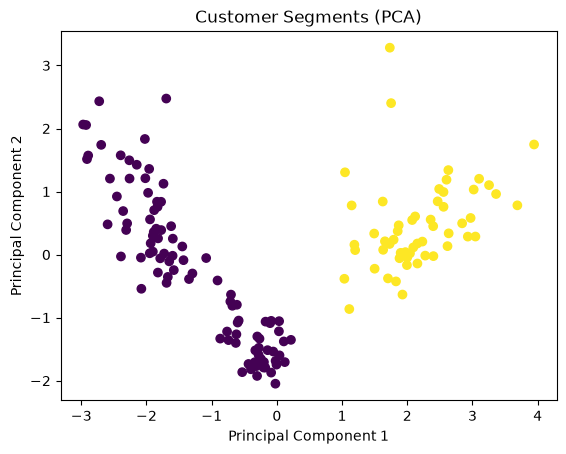

In [62]:
# TODO: project Xs to 2D with PCA and scatter it, colored by df["cluster"]
pcs = PCA(n_components=2).fit_transform(Xs)
plt.scatter(pcs[:,0], pcs[:,1], c=df["cluster"])
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Customer Segments (PCA)")
plt.show()

## Step 7: Profile and interpret the segments

Summarize each cluster by the average of each spend column (and how many customers are in it),
then describe each segment in plain words.

In [63]:
# TODO: build a profile table of per-cluster averages
cluster_means = df.groupby("cluster")[spend_cols].mean().round(0)
df["cluster"].value_counts()
print("Average spending by cluster:")
display(cluster_means)

print("Number of customers in each cluster:")
display(df["cluster"].value_counts().sort_index())

Average spending by cluster:


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
cluster,,,,,,
0,13872.0,2996.0,3373.0,3870.0,1055.0,1895.0
1,4128.0,9614.0,15824.0,1545.0,6310.0,1660.0


Number of customers in each cluster:


cluster
0    95
1    55
Name: count, dtype: int64

## Step 8: Findings

1. **How many clusters did you choose, and why?** 

I choose 2 clusters because the silhouette score was the highest for k=2. Increasing past 2 clusters would mean worse seperation, and the elbow method supported a small amount of clusters as well. 

2. **Describe each segment** in plain language. What kind of customer is it (for example, a grocery-heavy retailer vs a fresh-and-frozen restaurant supplier)?

Cluster 0 contains 95 customers and spend their money on primarily fresh food. They have the highest average spending on Fresh products ($13,872) and relatively high Frozen spending ($3,870). This could represent fresh-and-frozen resterans suppliers that rely heavily on fresh products. Cluster 1 contains 55 customers and spends more money grocery and milk. They have an average spending of $15,824 on Grocery, $9,614 on Milk, and $6,310 on Detergents/Paper. This group could represent grocery-heavy retailers.

3. **One action per segment:** what should the distributor do differently for each group?

Both distributors should focus heavily on their specific customer base. As an improvement for Cluster 0, the distributor could focus on reliable Fresh and Frozen product inventory and offer promotions on those products. For Cluster 1, the distributor could focus on Grocery, Milk, and Detergents/Paper products and create bulk-order discounts for those categories.

4. **One limitation:** what would you want to check or try next (different k, more features, outliers)?

One limitation is that the clustering only uses six spending categories, which is very limited. Separating categories such as grocery and fresh into more specific groups could help. Other information, such as customer location, business type, order or frequency could also be added to help with creating more meaningful customer segments.

## Submission checklist

- This notebook, renamed `Lastnames_Clustering.ipynb`, all cells run with output showing